# Section 1 — Import Libraries & Configuration

In [1]:
# # ============================================================
# # Import Libraries
# # ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import callbacks
from tensorflow.keras import regularizers
from tensorflow.keras import optimizers

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# # ============================================================
# # Project Directory
# # ============================================================
  
PROJECT_DIR = "C:/Users/aurna/Documents/brac_thesis"

In [3]:
METADATA_DIR = os.path.join(
    PROJECT_DIR,
    "metadata"
)

In [4]:
# # ============================================================
# # Dataset Files
# # ============================================================

TRAIN_CSV = os.path.join(
    METADATA_DIR,
    "train.csv"
)

VALIDATION_CSV = os.path.join(
    METADATA_DIR,
    "validation.csv"
)

TEST_CSV = os.path.join(
    METADATA_DIR,
    "test.csv"
)

METADATA_PATH = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

print("Dataset Paths Ready")

Dataset Paths Ready


In [5]:
# ============================================================
# Random Seed
# ============================================================

SEED = 42

random.seed(SEED)

np.random.seed(SEED)

tf.random.set_seed(SEED)

keras.utils.set_random_seed(SEED)

print("Random Seed Set Successfully")

Random Seed Set Successfully


In [6]:
# ============================================================
# Load Metadata
# ============================================================

with open(

    METADATA_PATH,

    "r"

) as file:

    metadata = json.load(

        file

    )

print("Metadata Loaded Successfully")

Metadata Loaded Successfully


In [7]:
# ============================================================
# Read Metadata
# ============================================================

IMAGE_HEIGHT = metadata["image_height"]

IMAGE_WIDTH = metadata["image_width"]

CHANNELS = metadata["channels"]

CLASS_NAMES = metadata["labels"]

LABEL_TO_INDEX = metadata["label_to_index"]

INDEX_TO_LABEL = metadata["index_to_label"]

NUM_CLASSES = metadata["total_labels"]

print("=" * 70)

print("DATASET INFORMATION")

print("=" * 70)

print(f"Image Size        : {IMAGE_HEIGHT} x {IMAGE_WIDTH}")

print(f"Channels          : {CHANNELS}")

print(f"Total Images      : {metadata['total_images']}")

print(f"Total Labels      : {NUM_CLASSES}")

DATASET INFORMATION
Image Size        : 224 x 224
Channels          : 3
Total Images      : 9271
Total Labels      : 12


In [8]:
# ============================================================
# Model Paths
# ============================================================

MODELS_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(
    MODELS_DIR,
    exist_ok=True
)

MODEL_PATH = os.path.join(
    MODELS_DIR,
    "skin_condition_identifier.keras"
)

HISTORY_PATH = os.path.join(
    MODELS_DIR,
    "training_history.json"
)

print("Model Paths Ready")

Model Paths Ready


In [9]:
# ============================================================
# Training Configuration
# ============================================================

BATCH_SIZE = 32

INITIAL_EPOCHS = 300

INITIAL_LEARNING_RATE = 1e-3

print("=" * 70)

print("TRAINING CONFIGURATION")

print("=" * 70)

print(f"Batch Size      : {BATCH_SIZE}")

print(f"Epochs          : {INITIAL_EPOCHS}")

print(f"Learning Rate   : {INITIAL_LEARNING_RATE}")

TRAINING CONFIGURATION
Batch Size      : 32
Epochs          : 300
Learning Rate   : 0.001


In [10]:
# ============================================================
# Class Labels
# ============================================================

print("=" * 70)

print("LABELS")

print("=" * 70)

for index, label in enumerate(

    CLASS_NAMES

):

    print(

        f"{index} : {label}"

    )

LABELS
0 : Acne_Mild
1 : Acne_Moderate
2 : Acne_Severe
3 : Burn_Mild
4 : Burn_Moderate
5 : Burn_Severe
6 : Eczema_Mild
7 : Eczema_Moderate
8 : Eczema_Severe
9 : Normal_Dry
10 : Normal_Normal
11 : Normal_Oily


In [11]:
# ============================================================
# TensorFlow Information
# ============================================================

print("=" * 70)

print("TENSORFLOW")

print("=" * 70)

print(

    "Version :",

    tf.__version__

)

print(

    "GPU Available :",

    len(

        tf.config.list_physical_devices(

            "GPU"

        )

    ) > 0

)

TENSORFLOW
Version : 2.21.0
GPU Available : False


# Section 2 — Load Dataset

In [12]:
# ============================================================
# Section 2 : Load CSV Files
# ============================================================

train_df = pd.read_csv(

    TRAIN_CSV

)

validation_df = pd.read_csv(

    VALIDATION_CSV

)

test_df = pd.read_csv(

    TEST_CSV

)

print("CSV Files Loaded Successfully")

CSV Files Loaded Successfully


In [13]:
# ============================================================
# Dataset Preview
# ============================================================

print("=" * 70)

print("TRAIN DATASET")

print("=" * 70)

display(

    train_df.head()

)

TRAIN DATASET


,filepath,filename,disease,severity,label
0,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_001.jpg,acne,mild,Acne_Mild
1,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_002.png,acne,mild,Acne_Mild
2,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_003.jpg,acne,mild,Acne_Mild
3,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_004.jpg,acne,mild,Acne_Mild
4,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_005.jpg,acne,mild,Acne_Mild


In [14]:
# ============================================================
# Dataset Information
# ============================================================

print("=" * 70)

print("DATASET SIZE")

print("=" * 70)

print(f"Training Samples     : {len(train_df)}")

print(f"Validation Samples   : {len(validation_df)}")

print(f"Testing Samples      : {len(test_df)}")

DATASET SIZE
Training Samples     : 7021
Validation Samples   : 1187
Testing Samples      : 1063


In [15]:
# ============================================================
# Convert Labels to Integer
# ============================================================

train_df["label_index"] = train_df["label"].map(

    LABEL_TO_INDEX

)

validation_df["label_index"] = validation_df["label"].map(

    LABEL_TO_INDEX

)

test_df["label_index"] = test_df["label"].map(

    LABEL_TO_INDEX

)

print("Labels Converted Successfully")

Labels Converted Successfully


In [16]:
# ============================================================
# Extract Dataset Columns
# ============================================================

train_image_paths = train_df["filepath"].values

train_labels = train_df["label_index"].values

validation_image_paths = validation_df["filepath"].values

validation_labels = validation_df["label_index"].values

test_image_paths = test_df["filepath"].values

test_labels = test_df["label_index"].values

print("Dataset Columns Extracted")

Dataset Columns Extracted


In [17]:
# ============================================================
# Image Loading Function
# ============================================================

def load_image(

    image_path,

    label

):

    image = tf.io.read_file(

        image_path

    )

    image = tf.io.decode_image(

        image,

        channels=CHANNELS,

        expand_animations=False

    )

    image.set_shape(

        [

            IMAGE_HEIGHT,

            IMAGE_WIDTH,

            CHANNELS

        ]

    )

    image = tf.cast(

        image,

        tf.float32

    )

    label = tf.one_hot(

        label,

        depth=NUM_CLASSES,

        dtype=tf.float32

    )

    return image, label

print("Image Loader Ready")

Image Loader Ready


In [18]:
# ============================================================
# Create TensorFlow Dataset
# ============================================================

train_dataset = tf.data.Dataset.from_tensor_slices(

    (

        train_image_paths,

        train_labels

    )

)

validation_dataset = tf.data.Dataset.from_tensor_slices(

    (

        validation_image_paths,

        validation_labels

    )

)

test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_image_paths,

        test_labels

    )

)

print("TensorFlow Datasets Created")

TensorFlow Datasets Created


In [19]:
# ============================================================
# Load Images
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.map(

    load_image,

    num_parallel_calls=AUTOTUNE

)

validation_dataset = validation_dataset.map(

    load_image,

    num_parallel_calls=AUTOTUNE

)

test_dataset = test_dataset.map(

    load_image,

    num_parallel_calls=AUTOTUNE

)

print("Images Loaded Successfully")

Images Loaded Successfully


In [20]:
# ============================================================
# Dataset Pipeline
# ============================================================

train_dataset = (

    train_dataset

    .shuffle(

        len(train_df),

        seed=SEED

    )

    .batch(

        BATCH_SIZE

    )

    .prefetch(

        AUTOTUNE

    )

)

validation_dataset = (

    validation_dataset

    .batch(

        BATCH_SIZE

    )

    .prefetch(

        AUTOTUNE

    )

)

test_dataset = (

    test_dataset

    .batch(

        BATCH_SIZE

    )

    .prefetch(

        AUTOTUNE

    )

)

print("Dataset Pipeline Ready")

Dataset Pipeline Ready


In [21]:
# ============================================================
# Verify Dataset
# ============================================================

for images, labels in train_dataset.take(1):

    print("=" * 70)

    print("TRAIN DATA")

    print("=" * 70)

    print("Image Batch Shape :", images.shape)

    print("Label Batch Shape :", labels.shape)

    print()

    print("First Label Vector")

    print(labels[0].numpy())

TRAIN DATA
Image Batch Shape : (32, 224, 224, 3)
Label Batch Shape : (32, 12)

First Label Vector
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]


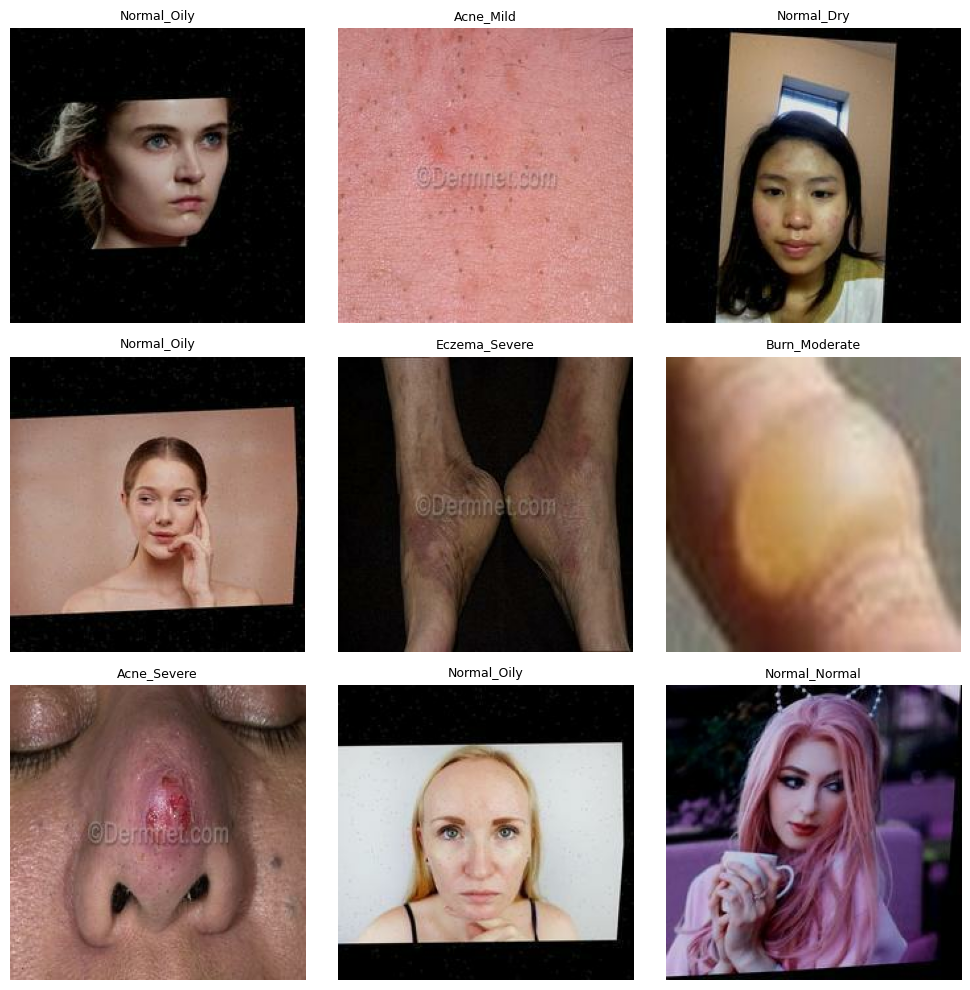

In [22]:
# ============================================================
# Sample Images
# ============================================================

plt.figure(

    figsize=(10, 10)

)

for images, labels in train_dataset.take(1):

    for index in range(9):

        plt.subplot(

            3,

            3,

            index + 1

        )

        plt.imshow(

            tf.cast(

                images[index],

                tf.uint8

            )

        )

        label_index = tf.argmax(

            labels[index]

        ).numpy()

        plt.title(

            CLASS_NAMES[label_index],

            fontsize=9

        )

        plt.axis("off")

plt.tight_layout()

plt.show()

# Section 3 — Data Augmentation

In [23]:
# ============================================================
# Section 3 : Data Augmentation
# ============================================================

data_augmentation = keras.Sequential(

    [

        layers.RandomFlip(

            mode="horizontal"

        ),

        layers.RandomRotation(

            factor=0.05

        ),

        layers.RandomZoom(

            height_factor=0.10,

            width_factor=0.10

        ),

    ],

    name="Data_Augmentation"

)

print("Data Augmentation Pipeline Created")

Data Augmentation Pipeline Created


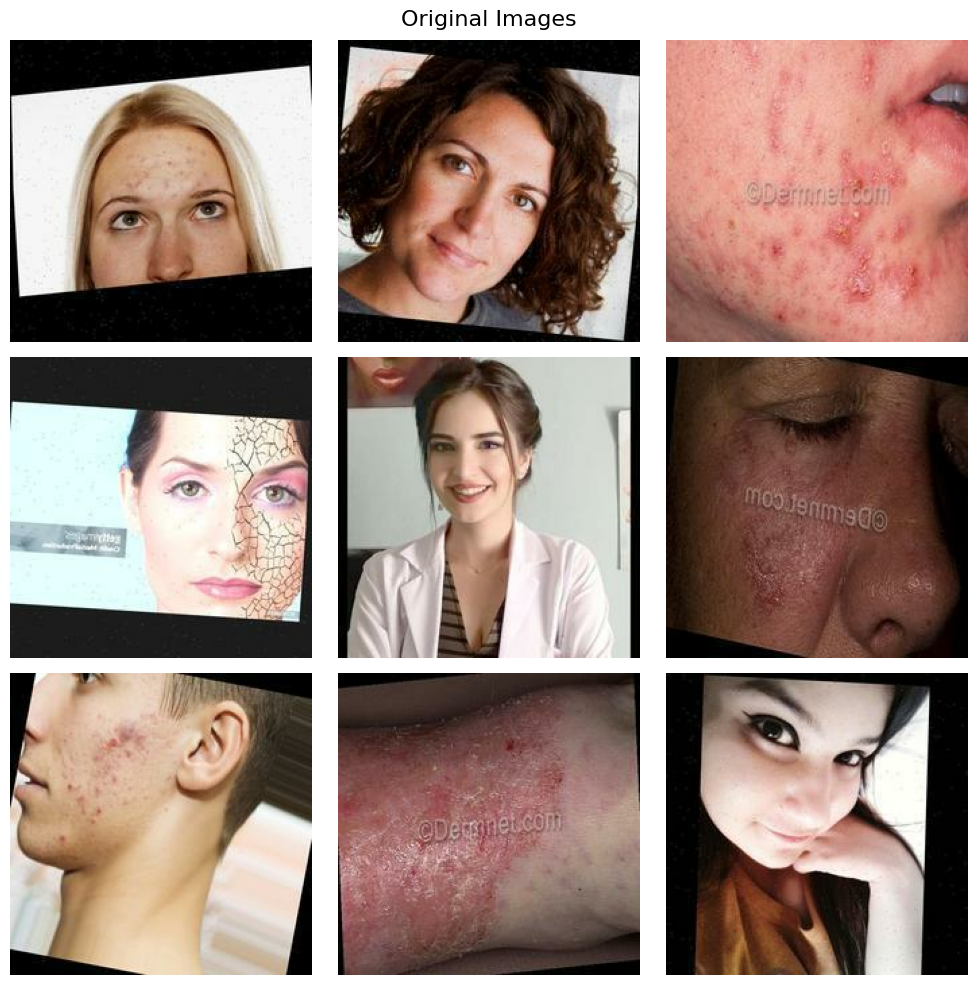

In [24]:
# ============================================================
# Original Images
# ============================================================

for images, labels in train_dataset.take(1):

    sample_images = images[:9]

    break

plt.figure(

    figsize=(10, 10)

)

for index in range(9):

    plt.subplot(

        3,

        3,

        index + 1

    )

    plt.imshow(

        tf.cast(

            sample_images[index],

            tf.uint8

        )

    )

    plt.axis("off")

plt.suptitle(

    "Original Images",

    fontsize=16

)

plt.tight_layout()

plt.show()

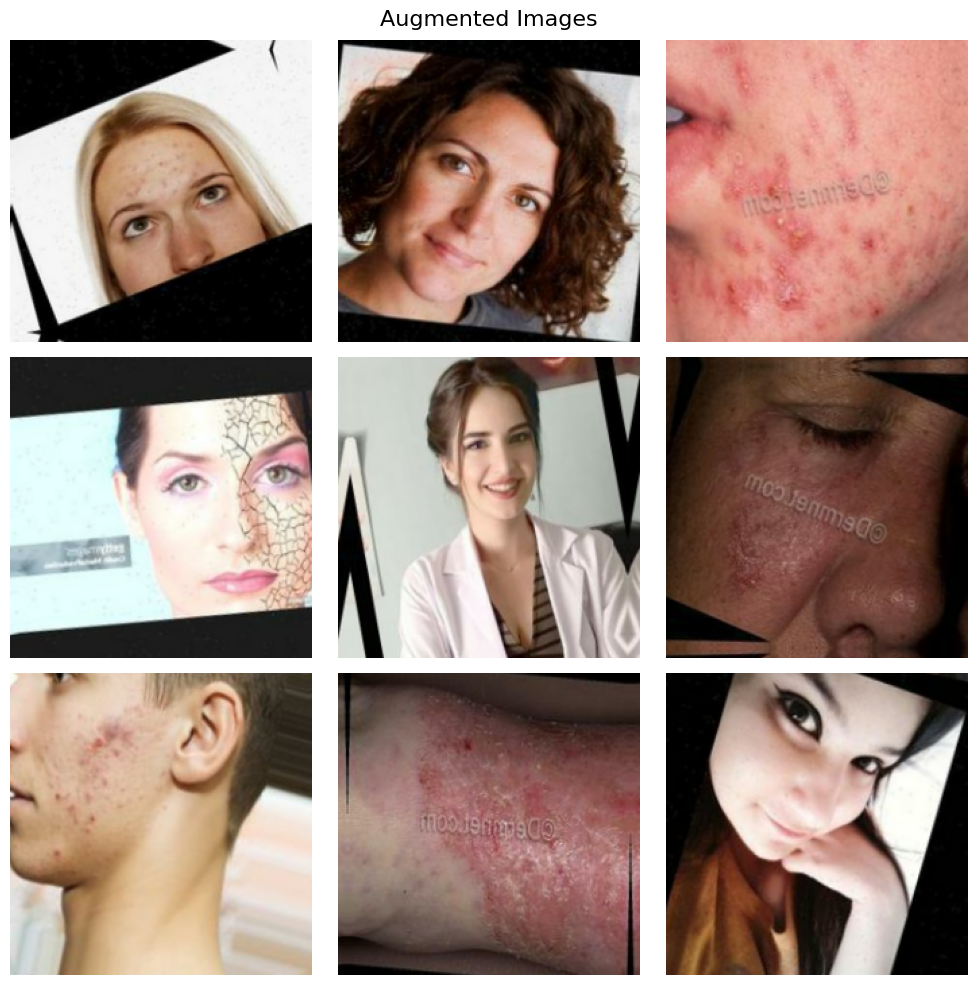

In [25]:
# ============================================================
# Augmented Images
# ============================================================

augmented_images = data_augmentation(

    sample_images,

    training=True

)

plt.figure(

    figsize=(10, 10)

)

for index in range(9):

    plt.subplot(

        3,

        3,

        index + 1

    )

    plt.imshow(

        tf.cast(

            augmented_images[index],

            tf.uint8

        )

    )

    plt.axis("off")

plt.suptitle(

    "Augmented Images",

    fontsize=16

)

plt.tight_layout()

plt.show()

# Section 4 — Build Model

In [26]:
base_model = tf.keras.applications.MobileNetV3Small(

    include_top=False,

    weights="imagenet",

    input_shape=(
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    ),

    include_preprocessing=True

)

# Freeze pretrained layers initially
base_model.trainable = False

print("MobileNetV3Small Loaded Successfully")


MobileNetV3Small Loaded Successfully


In [27]:
# ============================================================
# Build MobileNetV3Small Model
# ============================================================

inputs = layers.Input(

    shape=(
        IMAGE_HEIGHT,
        IMAGE_WIDTH,
        CHANNELS
    ),

    name="Input_Image"

)


# ============================================================
# Data Augmentation
# ============================================================

x = data_augmentation(inputs)


# ============================================================
# MobileNetV3Small Feature Extraction
# ============================================================

mobilenet_features = base_model(

    x,

    training=False

)

mobilenet_features = layers.GlobalAveragePooling2D(

    name="GlobalAveragePooling"

)(mobilenet_features)


# ============================================================
# Classification Head
# ============================================================

x = layers.BatchNormalization(

    name="BatchNormalization"

)(mobilenet_features)

In [28]:
# x = layers.Dense(
#     256,
#     activation="relu",
#     kernel_regularizer=regularizers.l2(1e-4),
#     name="Dense_256"
# )(x)

# x = layers.Dropout(0.30, name="Dropout_1")(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="Dense_128"
)(x)

x = layers.Dropout(0.30, name="Dropout_1")(x)

x = layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4),
    name="Dense_64"
)(x)

x = layers.Dropout(0.30, name="Dropout_2")(x)

In [29]:
# ============================================================
# Output Layer
# ============================================================

outputs = layers.Dense(

    NUM_CLASSES,

    activation="softmax",

    name="Prediction"

)(x)


# ============================================================
# Create MobileNetV3Small Model
# ============================================================

model = keras.Model(

    inputs=inputs,

    outputs=outputs,

    name="Model_skin_condition"

)

print("MobileNetV3Small Model Created Successfully")

MobileNetV3Small Model Created Successfully


In [30]:
# ============================================================
# Model Summary
# ============================================================

model.summary()

Model: "Model_skin_condition"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input_Image (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Data_Augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Small (Functional)        │ (None, 7, 7, 576)           │         939,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ GlobalAveragePooling                 │ (None, 576)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ BatchNormalization                   │ (None, 576)                 │           2,304 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dense_128 (Dense)                    │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dense_64 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Prediction (Dense)                   │ (None, 12)                  │             780 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,024,316 (3.91 MB)

 Trainable params: 84,044 (328.30 KB)

 Non-trainable params: 940,272 (3.59 MB)

In [31]:
# ============================================================
# Verify Output Layer
# ============================================================

print("=" * 70)

print("OUTPUT LAYER")

print("=" * 70)

print(

    "Activation :",

    model.layers[-1].activation.__name__

)

print(

    "Output Shape :",

    model.output_shape

)

OUTPUT LAYER
Activation : softmax
Output Shape : (None, 12)


# Section 5 — Compile Model

In [32]:
# ============================================================
# Section 5 : Optimizer
# ============================================================

optimizer = optimizers.Adam(

    learning_rate=INITIAL_LEARNING_RATE

)

print("Optimizer Created Successfully")

Optimizer Created Successfully


In [33]:
# ============================================================
# Compile Model
# ============================================================

model.compile(

    optimizer=optimizer,

    loss=tf.keras.losses.BinaryCrossentropy(),

    metrics=[

        tf.keras.metrics.CategoricalAccuracy(
            
            name="accuracy"
        
        ),

        tf.keras.metrics.Precision(

            name="precision"

        ),

        tf.keras.metrics.Recall(

            name="recall"

        ),

        tf.keras.metrics.AUC(

            name="auc"

        )

    ]

)

print("Model Compiled Successfully")

Model Compiled Successfully


In [34]:
# ============================================================
# Training Configuration
# ============================================================

print("=" * 70)

print("MODEL CONFIGURATION")

print("=" * 70)

print(f"Loss Function   : BinaryCrossentropy")

print(f"Optimizer       : Adam")

print(f"Learning Rate   : {INITIAL_LEARNING_RATE}")

print(f"Output Layer    : Sigmoid")

print(f"Total Classes   : {NUM_CLASSES}")

MODEL CONFIGURATION
Loss Function   : BinaryCrossentropy
Optimizer       : Adam
Learning Rate   : 0.001
Output Layer    : Sigmoid
Total Classes   : 12


# Section 6 — Callbacks

In [35]:
# ============================================================
# Section 6 : Model Checkpoint
# ============================================================

model_checkpoint = callbacks.ModelCheckpoint(

    filepath=MODEL_PATH,

    monitor="val_loss",

    mode="min",

    save_best_only=True,

    verbose=1

)

print("Model Checkpoint Ready")

Model Checkpoint Ready


In [36]:
# ============================================================
# Reduce Learning Rate
# ============================================================

reduce_learning_rate = callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=3,

    min_lr=1e-6,

    verbose=1

)

print("ReduceLROnPlateau Ready")

ReduceLROnPlateau Ready


In [37]:
# ============================================================
# Early Stopping
# ============================================================

early_stopping = callbacks.EarlyStopping(

    monitor="val_loss",

    patience=6,

    restore_best_weights=True,

    verbose=1

)

print("EarlyStopping Ready")

EarlyStopping Ready


In [38]:
# ============================================================
# Callback List
# ============================================================

callback_list = [

    model_checkpoint,

    reduce_learning_rate,

    early_stopping

]

print("Callbacks Created Successfully")

Callbacks Created Successfully


In [39]:
# ============================================================
# Callback Configuration
# ============================================================

print("=" * 70)

print("CALLBACK CONFIGURATION")

print("=" * 70)

print("Model Checkpoint   : Enabled")

print("ReduceLROnPlateau  : Enabled")

print("EarlyStopping      : Enabled")

CALLBACK CONFIGURATION
Model Checkpoint   : Enabled
ReduceLROnPlateau  : Enabled
EarlyStopping      : Enabled


# Section 7 — Train Model

In [ ]:
# ============================================================
# Section 7 : Model Training
# ============================================================

history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=INITIAL_EPOCHS,

    callbacks=callback_list,

    verbose=1

)

print("Model Training Completed Successfully")

Epoch 1/300
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.2610 - auc: 0.7434 - loss: 0.3720 - precision: 0.3522 - recall: 0.1301
Epoch 1: val_loss improved from None to 0.20809, saving model to C:/Users/aurna/Documents/brac_thesis\models\skin_condition_identifier.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 656s 3s/step - accuracy: 0.3386 - auc: 0.8303 - loss: 0.2888 - precision: 0.4391 - recall: 0.2038 - val_accuracy: 0.5013 - val_auc: 0.9306 - val_loss: 0.2081 - val_precision: 0.6759 - val_recall: 0.2477 - learning_rate: 0.0010
Epoch 2/300
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.4607 - auc: 0.9102 - loss: 0.2197 - precision: 0.5338 - recall: 0.3248
Epoch 2: val_loss improved from 0.20809 to 0.18189, saving model to C:/Users/aurna/Documents/brac_thesis\models\skin_condition_identifier.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 154s 386ms/step - accuracy: 0.4682 - auc: 0.9150 - loss: 0.2141 - precision: 0.5436 - recall: 0.3366 - val_accuracy: 0.5425 - val_auc: 0.9454 - val_lo

In [ ]:
# ============================================================
# Save Training History
# ============================================================

history_dict = history.history

with open(

    HISTORY_PATH,

    "w"

) as file:

    json.dump(

        history_dict,

        file,

        indent=4

    )

print("Training History Saved Successfully")

In [ ]:
# ============================================================
# Load Best Model
# ============================================================

model = keras.models.load_model(

    MODEL_PATH

)

print("Best Model Loaded Successfully")

In [ ]:
# ============================================================
# Training Summary
# ============================================================

print("=" * 70)

print("TRAINING COMPLETED")

print("=" * 70)

print(

    f"Total Epochs : {len(history.history['loss'])}"

)

print(

    f"Best Validation Loss : {min(history.history['val_loss']):.4f}"

)

print(

    f"Final Training Loss : {history.history['loss'][-1]:.4f}"

)

print(

    f"Final Validation Loss : {history.history['val_loss'][-1]:.4f}"

)

# Section 8 — Training History

In [ ]:
# ============================================================
# Section 8 : Load Training History
# ============================================================

with open(

    HISTORY_PATH,

    "r"

) as file:

    history_dict = json.load(

        file

    )

print("Training History Loaded Successfully")

In [ ]:
# ============================================================
# Training & Validation Loss
# ============================================================

plt.figure(

    figsize=(10, 5)

)

plt.plot(

    history_dict["loss"],

    label="Training Loss",

    linewidth=2

)

plt.plot(

    history_dict["val_loss"],

    label="Validation Loss",

    linewidth=2

)

plt.title(

    "Training and Validation Loss"

)

plt.xlabel(

    "Epoch"

)

plt.ylabel(

    "Loss"

)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/traning_validation_loss.png",
    dpi=300,
    bbox_inches="tight",
    transparent=False
)

plt.show()

In [ ]:
# ============================================================
# Training & Validation Accuracy
# ============================================================

plt.figure(

    figsize=(10, 5)

)

plt.plot(

    history_dict["accuracy"],

    label="Training Accuracy",

    linewidth=2

)

plt.plot(

    history_dict["val_accuracy"],

    label="Validation Accuracy",

    linewidth=2

)

plt.title(

    "Training and Validation Accuracy"

)

plt.xlabel(

    "Epoch"

)

plt.ylabel(

    "Accuracy"

)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/traning_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight",
    transparent=False
)

plt.show()

In [ ]:
# ============================================================
# Best Epoch
# ============================================================

best_epoch = np.argmin(

    history_dict["val_loss"]

) + 1

best_loss = min(

    history_dict["val_loss"]

)

print("=" * 70)

print("BEST MODEL")

print("=" * 70)

print(f"Best Epoch            : {best_epoch}")

print(f"Best Validation Loss  : {best_loss:.4f}")

In [ ]:
# ============================================================
# Final Training Summary
# ============================================================

print("=" * 70)

print("FINAL TRAINING RESULTS")

print("=" * 70)

print(

    f"Training Accuracy     : {history_dict['accuracy'][-1]:.4f}"

)

print(

    f"Validation Accuracy   : {history_dict['val_accuracy'][-1]:.4f}"

)

print()

print(

    f"Training Loss         : {history_dict['loss'][-1]:.4f}"

)

print(

    f"Validation Loss       : {history_dict['val_loss'][-1]:.4f}"

)

print("=" * 70)

In [ ]:
# ============================================================
# Compare Training and Validation Performance
# ============================================================

print("=" * 65)
print("PERFORMANCE COMPARISON")
print("=" * 65)

train_results = model.evaluate(
    train_dataset,
    verbose=1,
    return_dict=True
)

validation_results = model.evaluate(
    validation_dataset,
    verbose=1,
    return_dict=True
)

print("\nTraining Performance (Evaluation Mode)")
print(f"Accuracy : {train_results['accuracy']:.4f}")
print(f"Loss     : {train_results['loss']:.4f}")

print("\nValidation Performance")
print(f"Accuracy : {validation_results['accuracy']:.4f}")
print(f"Loss     : {validation_results['loss']:.4f}")

print("\nAccuracy Gap:")
print(
    f"{(train_results['accuracy'] - validation_results['accuracy']) * 100:.2f}%"
)

print("=" * 65)